# Build a RAG Loan Assistant, Step by Step

**Project:** Bank of Maharashtra Loan Product Assistant

In this walkthrough we build a chat assistant that answers questions about Bank of Maharashtra
loans. It uses only the bank's official web pages and shows its sources. When it cannot find an
answer, it says so instead of guessing.

The technique is called **RAG (Retrieval-Augmented Generation)**. The idea is simple:

> Do not ask the language model to *remember* the answer. **Find** the right passages first,
> then ask the model to answer **from those passages only**.

### What you will learn

| Part | Topic | Key idea |
|---|---|---|
| 1 | Setup | Paths, settings, API keys kept out of the code |
| 2 | Collect the data | Scrape politely and keep a record of every page |
| 3 | Clean the data | Keep the content, drop the menus and footers |
| 4 | Chunk the data | Cut pages into small pieces without breaking tables |
| 5 | Embeddings and FAISS | Search by meaning |
| 6 | BM25 | Search by exact words |
| 7 | Hybrid search | Merge both rankings with Reciprocal Rank Fusion |
| 8 | Guardrails | Refuse off-topic questions before calling the model |
| 9 | Prompt | Give the model strict rules and numbered context |
| 10 | Language model | Groq first, Gemini as the fallback |
| 11 | Number check | Catch figures the model made up |
| 12 | The full pipeline | Question in, cited answer out |
| 13 | Evaluation | Measure quality honestly with 25 test questions |
| 14 | Cross-check | Prove this notebook matches the real project code |
| 15 | Next steps | Run the app, then try the exercises |

### Before you start

Run these from the project root, inside your virtual environment:

```bash
pip install -r requirements.txt
pip install -e .
pip install notebook matplotlib
```

Then copy `.env.example` to `.env` and add a free `GROQ_API_KEY` from
[console.groq.com](https://console.groq.com). A `GEMINI_API_KEY` is optional.
**Only one cell, in Part 12, calls a language model.** Without a key it skips itself politely,
and everything else still runs.

---
# Part 1: Setup

**What this cell does:** imports every library the notebook uses and finds the project folder.

**Why it matters:** each library has one clear job, so it helps to see them all in one place.
Finding the folder automatically means the notebook works wherever a student cloned the project.

In [1]:
import json
import re
import sys
import textwrap
import time
from dataclasses import dataclass, field
from datetime import date, datetime, timedelta, timezone
from decimal import Decimal
from pathlib import Path
from urllib.robotparser import RobotFileParser  # read robots.txt

import faiss  # very fast vector search
import matplotlib.pyplot as plt  # charts
import numpy as np  # number arrays
import pandas as pd  # tables
import requests  # download web pages
from bs4 import BeautifulSoup, Comment  # read HTML
from dotenv import dotenv_values  # read the .env file
from fastembed import TextEmbedding  # turn text into vectors, on the CPU, for free
from google import genai  # Gemini client (fallback model)
from google.genai import types as genai_types
from groq import Groq  # Groq client (main model)
from rank_bm25 import BM25Okapi  # keyword search

# Windows consoles can crash on characters such as the rupee sign. Notebooks do not need this.
if hasattr(sys.stdout, "reconfigure"):
    sys.stdout.reconfigure(encoding="utf-8")

# Walk up from this file (or the notebook's folder) until we find the project's data folder.
start = Path(globals().get("__file__", Path.cwd())).resolve()
ROOT = next(
    p for p in [start, *start.parents] if (p / "data" / "processed" / "chunks.jsonl").exists()
)
print("Project root found:", ROOT.name)

Project root found: bom-loan-assistant


**What this cell does:** defines every setting in one place. These values are the same as the
project's `src/loan_assistant/config.py`.

**Why it matters:** each number here is a design decision. When a student asks "why 5 chunks?",
this is the cell to come back to.

| Setting | Plain meaning |
|---|---|
| `CANDIDATES_K = 20` | Each search method brings back its 20 best chunks |
| `TOP_K = 5` | Only the best 5 chunks after merging go to the language model |
| `RRF_K = 60` | A smoothing number used when merging the two rankings (Part 7) |
| `MIN_SCORE = 0.68` | If the best chunk is less similar than this, refuse to answer (Part 8) |

In [2]:
DATA_DIR = ROOT / "data" / "processed"

EMBEDDING_MODEL = "BAAI/bge-small-en-v1.5"  # small model that runs locally
GROQ_MODEL = "openai/gpt-oss-120b"  # main language model

CANDIDATES_K = 20  # chunks each search method returns
TOP_K = 5  # chunks sent to the language model
RRF_K = 60  # smoothing constant for Reciprocal Rank Fusion
MIN_SCORE = 0.68  # below this best similarity, refuse (real questions >= 0.74, off-topic <= 0.66)

CHUNK_TARGET_WORDS = 300  # aim for chunks of this size
CHUNK_OVERLAP_WORDS = 50  # repeat a little text between neighbouring prose chunks

**What this cell does:** reads the API keys from `.env` and prints only whether each one exists.

**Why it matters:** this is a habit worth teaching on day one. **A key never goes in the code,
never goes in Git and is never printed.** The project's `.gitignore` already excludes `.env`.

In [3]:
env = dotenv_values(ROOT / ".env")
GROQ_API_KEY = env.get("GROQ_API_KEY") or ""
GEMINI_API_KEY = env.get("GEMINI_API_KEY") or ""
GEMINI_MODEL = env.get("GEMINI_MODEL") or "gemini-flash-latest"

print("Groq key:  ", "found" if GROQ_API_KEY else "missing")
print("Gemini key:", "found" if GEMINI_API_KEY else "missing (optional)")

Groq key:   found
Gemini key: found


**What this cell does:** adds a small helper that keeps printed text readable.

In [4]:
def show(text: str, width: int = 95, limit: int | None = None) -> None:
    """Print text wrapped to a readable width, optionally cut after `limit` characters."""
    if limit and len(text) > limit:
        text = text[:limit].rstrip() + " ..."
    for line in text.split("\n"):
        print(textwrap.fill(line, width) if line.strip() else "")

---
# Part 2: Collect the data

Every RAG system depends on its data. We use **only** the bank's official site, because an
assistant that quotes loan rates must quote the bank and not a blog.

**Being a polite scraper** means four things:

1. Read `robots.txt` and obey it.
2. Wait at least one second between requests.
3. Identify yourself honestly with a User-Agent.
4. Save what you fetched so you never ask for the same page twice.

**What this cell does:** shows those four rules as one small function. It is switched off by
default, so a class of students does not all hit the bank's website at once. The full version
with retries and a manifest is in `src/loan_assistant/scraping/fetch.py`.

In [5]:
RUN_LIVE_SCRAPE = False  # change to True to fetch one real page
BASE_URL = "https://bankofmaharashtra.bank.in"
USER_AGENT = "BoMLoanAssistantBot/0.1 (assessment project; polite crawler)"


def polite_get(url: str, delay_s: float = 1.0) -> str | None:
    """Fetch one page, following the polite-scraping rules. Returns None if robots.txt says no."""
    robots = RobotFileParser()
    robots.set_url(f"{BASE_URL}/robots.txt")
    robots.read()  # rule 1: read robots.txt
    if not robots.can_fetch(USER_AGENT, url):
        return None
    time.sleep(delay_s)  # rule 2: wait before asking
    response = requests.get(url, headers={"User-Agent": USER_AGENT}, timeout=20)  # rule 3
    response.raise_for_status()
    return response.text  # rule 4 (saving to disk) is handled by the project's Fetcher class


if RUN_LIVE_SCRAPE:
    page = polite_get(f"{BASE_URL}/personal-banking/loans/home-loan")
    print("Downloaded", len(page or ""), "characters")
else:
    print("Live scrape is off. We will use the data the project already collected.")

Live scrape is off. We will use the data the project already collected.


**What this cell does:** opens the **manifest**, the project's record of every URL it requested.

**Why it matters:** the manifest makes the data traceable. For each page it stores the HTTP
status, the time, the size and a checksum, so anyone can see exactly what the knowledge base was
built from.

**What to look for:** the `301` rows are pages that redirect away from the official site. The
scraper records those redirects but does not follow them.

In [6]:
manifest = pd.read_csv(ROOT / "data" / "raw" / "manifest.csv")
print("URLs requested:", len(manifest))
print(
    manifest.groupby(["type", "http_status"])
    .size()
    .rename("pages")
    .reset_index()
    .to_string(index=False)
)
print("\nScrape started (UTC):", manifest["fetched_at"].min())

URLs requested: 136
type  http_status  pages
html          200     88
html          301      2
 pdf          200     45
 xml          200      1

Scrape started (UTC): 2026-10-27T18:58:09+00:00


---
# Part 3: Clean the data

A raw web page is mostly menus, footers, buttons and scripts. If we indexed all of that, a search
for "home loan" would match every page's navigation menu.

**What this cell does:** shows the core idea of cleaning in about 20 lines:

1. Delete the tags that are never content (`script`, `nav`, `footer` and so on).
2. Find the main content area of the page.
3. Turn each table into a Markdown table, because rates and fees live in tables.
4. Return the plain text that is left.

We run it on `tests/fixtures/sample_tabbed_page.html`, a small test page built to look like the
bank's real pages.

In [7]:
NEVER_CONTENT = "script style noscript svg img iframe nav header footer aside button".split()


def table_to_markdown(table) -> str:
    """Turn an HTML table into a Markdown table."""
    rows = [
        [" ".join(cell.get_text(" ", strip=True).split()) for cell in row.find_all(["td", "th"])]
        for row in table.find_all("tr")
    ]
    rows = [row for row in rows if row]
    if not rows:
        return ""
    header = "| " + " | ".join(rows[0]) + " |"
    divider = "|" + "---|" * len(rows[0])
    body = ["| " + " | ".join(row) + " |" for row in rows[1:]]
    return "\n".join([header, divider, *body])


def simple_clean(html: str) -> str:
    """A teaching version of the cleaner: keep the content, drop the page furniture."""
    soup = BeautifulSoup(html, "lxml")
    for tag in soup(NEVER_CONTENT):  # step 1: remove what is never content
        tag.decompose()
    for comment in soup.find_all(string=lambda s: isinstance(s, Comment)):
        comment.extract()
    main = soup.select_one(".maincontent") or soup.body  # step 2: find the content area
    for table in main.find_all("table"):  # step 3: tables become Markdown
        table.replace_with("\n\n" + table_to_markdown(table) + "\n\n")
    lines = (line.strip() for line in main.get_text("\n").split("\n"))  # step 4: plain text
    return "\n".join(line for line in lines if line)


sample_html = (ROOT / "tests" / "fixtures" / "sample_tabbed_page.html").read_text(encoding="utf-8")
everything_visible = BeautifulSoup(sample_html, "lxml").get_text(" ")
cleaned = simple_clean(sample_html)

print("Words before cleaning:", len(everything_visible.split()))
print("Words after cleaning: ", len(cleaned.split()))
print("Menu text removed?    ", "MENU_ITEM_DEPOSITS" not in cleaned)
print("Script text removed?  ", "SECRET_SCRIPT_TEXT" not in cleaned)
print("\n--- Start of the cleaned text ---")
show(cleaned, limit=450)

Words before cleaning: 146
Words after cleaning:  103
Menu text removed?     True
Script text removed?   True

--- Start of the cleaned text ---
Sample Housing Loan Scheme
The scheme finances purchase of a house or flat for salaried and self-employed applicants.
Interest Rate
7.25
%P.A*
Get a Call Back
Apply Online
Features & Benefits
EMI Calculator
Features and benefits
Low EMI
Flexible repayment options
No Prepayment Penalty
None
| Information | Details |
|---|---|
| Interest Rate | 7.25 %P.A* |
| Loan amount | INR 50,00,000 or Rs.75 Lakh |
| Women concession | 0.05 per cent |
Principal ...


**What this cell does:** runs the project's real cleaner on the same page, so students can see
what a production version adds.

**Why it matters:** the idea takes 20 lines, but the real file takes more than 600. Look at what
our short version got wrong:
- "Get a Call Back" and "Apply Online" survived, because they are links and not buttons.
- It deleted every `<button>`. On this site the FAQ questions are stored in buttons, so they
  vanished without any error. The project hit this exact bug.
- It ran all the tabs together. The real cleaner keeps each tab as its own section.

That gap between a demo and a working system is one of the main lessons of this project.

In [8]:
sys.path.insert(0, str(ROOT / "src"))  # lets us import the real project code

from loan_assistant.processing.clean import clean_html  # noqa: E402

real_page = clean_html(sample_html)
print("Page title:", real_page.title)
for section in real_page.sections:
    print(f"  section: {section.heading:<28} {section.words} words")

Page title: Sample Housing Loan Scheme
  section: Overview                     18 words
  section: Features & Benefits          11 words
  section: At a Glance                  30 words
  section: FAQs                         16 words


**What this cell does:** reads the statistics from the real cleaning run across all pages.

**What to look for:** about three quarters of the visible words on the raw pages were menus,
footers and buttons. Without cleaning, most of what we indexed would be noise.

In [9]:
stats = json.loads((DATA_DIR / "stats.json").read_text(encoding="utf-8"))
removed_pct = 100 * stats["words_dropped_as_page_chrome"] / stats["raw_visible_words_html"]

print("Web pages kept:     ", stats["pages_html"])
print("PDF documents kept: ", stats["pages_pdf"])
print("Words kept:         ", f"{stats['words_total']:,}")
print("Tables kept:        ", stats["tables"])
print(f"Page chrome removed: {removed_pct:.0f}% of the words visible on the raw web pages")
print("\nPages by loan area:")
print(pd.Series(stats["by_category"]).sort_values(ascending=False).to_string())

Web pages kept:      86
PDF documents kept:  3
Words kept:          72,441
Tables kept:         115
Page chrome removed: 74% of the words visible on the raw web pages

Pages by loan area:
agri         19
msme         19
other        14
home         11
personal      8
vehicle       6
education     5
property      3
rates         2
gold          1
charges       1


---
# Part 4: Chunk the data

A whole page is too long to give a language model, and it would dilute the search. So we cut each
page into **chunks**. Three rules make the chunks useful:

| Rule | Why |
|---|---|
| Never cross a section boundary | "Eligibility" and "Fees" stay separate |
| Never cut a table in the middle | Half a rate table gives wrong answers |
| Put the product name on top of every chunk | A chunk saying "84 months" must say *which loan* |

**What this cell does:** implements those rules in a simple chunker. The small overlap repeats the
end of one prose chunk at the start of the next, so a sentence near the cut is not lost.

**What to look for:** the last section is one big table of 497 words, and our simple chunker
keeps it as one oversized chunk. It never cuts a table, but it never splits a long one either.
The real chunker in the next cell fixes that.

In [10]:
def context_header(product: str, section: str, url: str) -> str:
    """The line placed on top of every chunk, so a chunk still makes sense on its own."""
    return f"Product: {product} | Section: {section} | Source: {url}"


def simple_chunks(product: str, section: str, text: str, url: str) -> list[str]:
    """Pack paragraphs and whole tables into chunks of about CHUNK_TARGET_WORDS."""
    blocks = [b.strip() for b in re.split(r"\n\s*\n", text) if b.strip()]  # blank line = new block
    chunks, current, words = [], [], 0
    for block in blocks:
        size = len(block.split())
        if (
            current and words + size > CHUNK_TARGET_WORDS
        ):  # this block would not fit: close the chunk
            chunks.append("\n\n".join(current))
            last = current[-1]
            # Overlap: carry the last block forward if it is short prose (never a table).
            keep = len(last.split()) <= CHUNK_OVERLAP_WORDS and not last.startswith("|")
            current, words = ([last], len(last.split())) if keep else ([], 0)
        current.append(block)  # a table is one block, so it is never cut here
        words += size
    if current:
        chunks.append("\n\n".join(current))
    return [f"{context_header(product, section, url)}\n\n{body}" for body in chunks]


# Try it on one real product from the knowledge base.
products = [
    json.loads(line)
    for line in (DATA_DIR / "loan_products.jsonl").read_text(encoding="utf-8").splitlines()
    if line
]
flexi = next(p for p in products if "flexi" in p["url"])

print("Product:", flexi["product"])
for section_name, section_text in flexi["sections"].items():
    pieces = simple_chunks(flexi["product"], section_name, section_text, flexi["url"])
    print(f"  {section_name:<30} {len(section_text.split()):>4} words -> {len(pieces)} chunk(s)")

Product: Maha Super Flexi Housing Loan Scheme (Term Loan linked with Saving Account.)
  Overview                         61 words -> 1 chunk(s)
  Key Features                    117 words -> 1 chunk(s)
  Benefits to the borrowers        26 words -> 1 chunk(s)
  Maha Super Flexi Housing Loan - for New or existing house/flat and extension of existing house/flat  497 words -> 1 chunk(s)


**What this cell does:** loads the 415 chunks the project really uses. The real chunker
(`src/loan_assistant/processing/chunk.py`) follows the same rules with more care. For example,
it splits a very long table into row groups and repeats the header row on each group.

**What to look for:** the first line of the sample chunk is the context header. The chart shows
that most chunks stay at or below the 300-word target.

Chunks:       415
Median words: 214
Largest:      450 words
At or under 300 words: 97%
Flexi scheme chunks in the real set: 5
Fields:       id, text, product, section, url, category, scraped_at, type, words

--- One chunk ---
Product: Loan Against Deposit (LAD) | Section: Unlock Financial Flexibility without Breaking
Your Fixed Deposit: Loan Against Deposit by Bank of Maharashtra | Source:
https://bankofmaharashtra.bank.in/lad

A Fixed Deposit (FD) is a reliable way to save and grow your wealth over time. However,
financial emergencies can arise unexpectedly, and you may need immediate funds without
disturbing your long-term financial goals. That's why we offer a convenient Loan Against
Deposit (LAD) facility, allowi ...


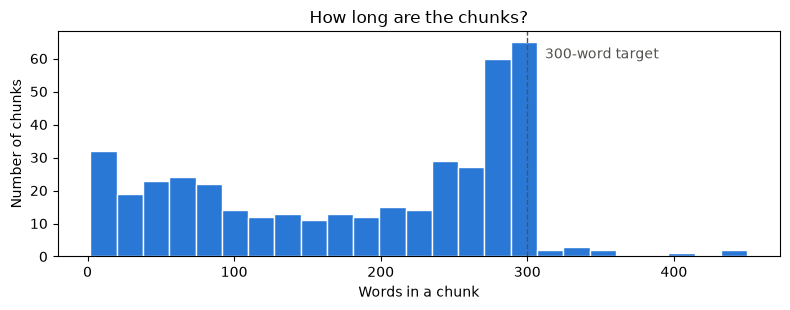

In [11]:
chunks = [
    json.loads(line)
    for line in (DATA_DIR / "chunks.jsonl").read_text(encoding="utf-8").splitlines()
    if line
]
word_counts = [c["words"] for c in chunks]

print("Chunks:      ", len(chunks))
print("Median words:", int(np.median(word_counts)))
print("Largest:     ", max(word_counts), "words")
at_or_under = np.mean(np.array(word_counts) <= CHUNK_TARGET_WORDS)
print(f"At or under {CHUNK_TARGET_WORDS} words: {at_or_under:.0%}")
print("Flexi scheme chunks in the real set:", sum(c["url"] == flexi["url"] for c in chunks))
print("Fields:      ", ", ".join(chunks[0].keys()))
print("\n--- One chunk ---")
show(next(c for c in chunks if "lad" in c["id"])["text"], limit=500)

plt.figure(figsize=(8, 3.2))
plt.hist(word_counts, bins=25, color="#2a78d6", edgecolor="white")
plt.axvline(CHUNK_TARGET_WORDS, color="#52514e", linestyle="--", linewidth=1)
plt.text(CHUNK_TARGET_WORDS + 12, plt.ylim()[1] * 0.88, "300-word target", color="#52514e")
plt.title("How long are the chunks?")
plt.xlabel("Words in a chunk")
plt.ylabel("Number of chunks")
plt.tight_layout()
plt.show()

---
# Part 5: Embeddings and FAISS (search by meaning)

An **embedding** is a list of numbers that captures what a piece of text means. Texts with similar
meanings get similar numbers, even when they share no words.

**What this cell does:** loads the embedding model (a one-time download of about 70 MB the first
time) and gives two helper functions.

**Why two functions?** This model handles *questions* and *passages* slightly differently, so we
use `query_embed` for questions and `embed` for chunks.

**Why normalize?** We scale every vector to length 1. After that, a simple dot product between
two vectors equals their **cosine similarity**: close to 1 means very similar, close to 0 means
unrelated.

In [12]:
embedding_model = TextEmbedding(model_name=EMBEDDING_MODEL)


def normalize(vectors: np.ndarray) -> np.ndarray:
    """Scale every row to length 1, so a dot product equals cosine similarity."""
    return vectors / np.clip(np.linalg.norm(vectors, axis=1, keepdims=True), 1e-12, None)


def embed_passages(texts: list[str]) -> np.ndarray:
    """Embed document chunks."""
    return normalize(np.array(list(embedding_model.embed(texts, batch_size=32)), dtype=np.float32))


def embed_query(question: str) -> np.ndarray:
    """Embed one question."""
    return normalize(np.array(list(embedding_model.query_embed([question])), dtype=np.float32))


vector = embed_query("home loan interest rate")
print(
    "One question becomes", vector.shape[1], "numbers. The first five:", np.round(vector[0][:5], 3)
)

One question becomes 384 numbers. The first five: [ 0.021 -0.057  0.005 -0.031  0.004]


**What this cell does:** compares a question with three sentences.

**What to look for:** the first sentence shares almost no words with the question, yet it scores
clearly higher than the unrelated ones. *That is search by meaning.*

In [13]:
question = "How long can I take to repay my housing finance?"
sentences = [
    "The maximum tenure for a home loan is 30 years.",  # same meaning, different words
    "Gold ornaments can be pledged for a short-term loan.",  # same topic area, different meaning
    "The weather in Pune is pleasant in winter.",  # unrelated
]
scores = (embed_passages(sentences) @ embed_query(question).T).ravel()  # @ is the dot product

print("Question:", question, "\n")
for sentence, score in zip(sentences, scores, strict=True):
    print(f"  {score:.3f}  {sentence}")

Question: How long can I take to repay my housing finance? 

  0.681  The maximum tenure for a home loan is 30 years.
  0.568  Gold ornaments can be pledged for a short-term loan.
  0.372  The weather in Pune is pleasant in winter.


**What this cell does:** embeds all 415 chunks and stores them in a FAISS index.

**Why this index type?** `IndexFlatIP` compares the question with *every* chunk. That sounds slow,
but with only 415 chunks it is instant and always exact. Approximate indexes only pay off with
millions of vectors, so choosing one here would add complexity for no gain.

**Timing:** embedding is the slow step, and it can take a minute or two on a laptop CPU. It only
happens once, because the project saves the result in `index/`. Searching afterwards is instant.

In [14]:
started = time.perf_counter()
chunk_vectors = embed_passages([c["text"] for c in chunks])
faiss_index = faiss.IndexFlatIP(chunk_vectors.shape[1])  # exact inner-product search
faiss_index.add(chunk_vectors)

print(f"Embedded and indexed {faiss_index.ntotal} chunks in {time.perf_counter() - started:.1f} s")
print("Each vector has", faiss_index.d, "numbers")

Embedded and indexed 415 chunks in 113.0 s
Each vector has 384 numbers


**What this cell does:** defines vector search. It returns chunk positions, best first, along with
each chunk's cosine similarity. We keep the similarity for *every* chunk because the guardrail in
Part 8 needs it.

In [15]:
def vector_search(question: str) -> tuple[list[int], np.ndarray]:
    """Return (the CANDIDATES_K best chunk positions, the cosine similarity of every chunk)."""
    similarities, positions = faiss_index.search(embed_query(question), faiss_index.ntotal)
    cosine = np.zeros(faiss_index.ntotal, dtype=np.float32)
    cosine[positions[0]] = similarities[0]
    return [int(i) for i in positions[0][:CANDIDATES_K]], cosine


ranking, cosine = vector_search("What is the maximum tenure for a personal loan?")
for rank, i in enumerate(ranking[:3], start=1):
    print(f"{rank}. {cosine[i]:.3f}  {chunks[i]['product']}  ({chunks[i]['section']})")

1. 0.778  Loan against Property -for Individuals(LAP)  (Key Features of Loan Against Property)
2. 0.764  Topup Loan for Home loan borrowers  (Features & Benefits)
3. 0.756  Maha Saraswati Scheme  (4. What is the tenure of the scheme?)


---
# Part 6: BM25 (search by exact words)

Search by meaning has a blind spot: exact terms such as "LAD" or "fixed deposit" can get lost.
**BM25** is the classic keyword method behind many search engines. It rewards chunks that contain
the question's words, and gives more weight to words that are rare across all chunks.

**What this cell does:** builds the tokenizer and the BM25 index.

**Look at the tokenizer:** the pattern keeps `7.25` as one token, because numbers matter in a loan
assistant. It also removes common words such as "the" and "what", which tell us nothing.

In [16]:
TOKEN = re.compile(r"\d+(?:\.\d+)?|[a-z]+")
STOPWORDS = frozenset(
    "a an and are as at be by can do does for from has have how i if in is it me my of on or "
    "the their there this to was what when which who will with you your".split()
)


def tokenize(text: str) -> list[str]:
    """Lower-case words and numbers, with common function words removed."""
    return [t for t in TOKEN.findall(text.lower()) if t not in STOPWORDS]


bm25 = BM25Okapi([tokenize(c["text"]) for c in chunks])


def bm25_search(question: str) -> list[int]:
    """Return the best chunk positions by keyword score, ignoring chunks with no match."""
    scores = bm25.get_scores(tokenize(question))
    return [int(i) for i in np.argsort(-scores)[:CANDIDATES_K] if scores[i] > 0]


print("Tokens:", tokenize("What is the 7.25% rate for a Home Loan?"))
ranking = bm25_search("loan against fixed deposit")
print("\nBest keyword matches for 'loan against fixed deposit':")
for rank, i in enumerate(ranking[:3], start=1):
    print(f"{rank}. {chunks[i]['product']}  ({chunks[i]['section']})")

Tokens: ['7.25', 'rate', 'home', 'loan']

Best keyword matches for 'loan against fixed deposit':
1. Loan Against Deposit (LAD)  (Unlock Financial Flexibility without Breaking Your Fixed Deposit: Loan Against Deposit by Bank of Maharashtra)
2. Loan Against Deposit (LAD)  (Unlock Financial Flexibility without Breaking Your Fixed Deposit: Loan Against Deposit by Bank of Maharashtra)
3. Retail Loans  (Overview)


---
# Part 7: Hybrid search with Reciprocal Rank Fusion (RRF)

We now have two ranked lists, but their scores cannot be compared: a cosine of 0.8 and a BM25
score of 12 are on different scales. **RRF ignores the scores and uses only the positions:**

$$\text{RRF score} = \sum_{\text{each list}} \frac{1}{k + \text{rank}} \qquad (k = 60)$$

A chunk ranked well by *both* lists beats a chunk ranked first by only one.

**What this cell does:** defines RRF and tries it on a tiny example you can check on paper.

**What to look for:** A is 1st and 3rd. B is 2nd and 1st. B wins, narrowly, because it is strong
in both lists. C and D each appear in only one list, so they finish well behind A and B.

In [17]:
def rrf_fuse(rankings: list[list[int]], k: int = RRF_K) -> dict[int, float]:
    """Each list gives 1 / (k + rank) to every item it ranks. The scores simply add up."""
    scores: dict[int, float] = {}
    for ranking in rankings:
        for rank, item in enumerate(ranking, start=1):
            scores[item] = scores.get(item, 0.0) + 1.0 / (k + rank)
    return scores


names = {1: "A", 2: "B", 3: "C", 4: "D"}
by_meaning = [1, 2, 3]  # A, B, C
by_keyword = [2, 4, 1]  # B, D, A
for item, score in sorted(rrf_fuse([by_meaning, by_keyword]).items(), key=lambda pair: -pair[1]):
    print(f"Chunk {names[item]}: {score:.5f}")

Chunk B: 0.03252
Chunk A: 0.03227
Chunk D: 0.01613
Chunk C: 0.01587


**What this cell does:** defines the real search function, with two modes: `vector` (meaning only)
and `hybrid` (meaning and keywords). The small `Hit` class keeps the chunk together with its
scores, so we can show students *why* it was chosen.

In [18]:
@dataclass
class Hit:
    chunk: dict
    score: float  # RRF score in hybrid mode, cosine similarity in vector mode
    cosine: float  # similarity between question and chunk, always filled
    vector_rank: int | None  # position in the meaning search, None if not in its top 20
    bm25_rank: int | None  # position in the keyword search, None if not in its top 20


def search(question: str, mode: str = "hybrid", top_k: int = TOP_K) -> list[Hit]:
    """Return the best chunks for a question."""
    vector_ranking, cosine = vector_search(question)
    vector_rank = {i: r for r, i in enumerate(vector_ranking, start=1)}

    if mode == "vector":
        return [
            Hit(chunks[i], float(cosine[i]), float(cosine[i]), vector_rank[i], None)
            for i in vector_ranking[:top_k]
        ]

    bm25_ranking = bm25_search(question)
    bm25_rank = {i: r for r, i in enumerate(bm25_ranking, start=1)}
    fused = rrf_fuse([vector_ranking, bm25_ranking])
    # Equal RRF scores go to the chunk that is closer in meaning.
    best = sorted(fused, key=lambda i: (-fused[i], -cosine[i]))[:top_k]
    return [
        Hit(chunks[i], fused[i], float(cosine[i]), vector_rank.get(i), bm25_rank.get(i))
        for i in best
    ]

**What this cell does:** runs one of the project's real test questions through both modes.

**What to look for:** this is the clearest example of why the project uses hybrid search. The
question is about a loan against a fixed deposit, and the correct page is `/lad`. Meaning-only
search misses that page in its top 5. Keyword search picks up "fixed deposit", and hybrid brings
the page into the top 5.

In [19]:
question = "How much can I borrow against my fixed deposit and is there a processing fee?"
print("Question:", question)

for mode in ("vector", "hybrid"):
    print(f"\n--- {mode.upper()} ---")
    rows = [
        {
            "rank": n,
            "page": hit.chunk["url"].rsplit("/", 1)[-1][:42],
            "cosine": round(hit.cosine, 3),
            "meaning rank": hit.vector_rank or "-",
            "keyword rank": hit.bm25_rank or "-",
            "correct page?": "YES" if hit.chunk["url"].endswith("/lad") else "",
        }
        for n, hit in enumerate(search(question, mode), start=1)
    ]
    print(pd.DataFrame(rows).to_string(index=False))

Question: How much can I borrow against my fixed deposit and is there a processing fee?

--- VECTOR ---
 rank                  page  cosine  meaning rank keyword rank correct page?
    1       topup-home-loan   0.716             1            -              
    2 loan-against-property   0.702             2            -              
    3       service-charges   0.699             3            -              
    4       service-charges   0.688             4            -              
    5     educational-loans   0.687             5            -              

--- HYBRID ---
 rank                  page  cosine  meaning rank  keyword rank correct page?
    1             home-loan   0.678            10             3              
    2       service-charges   0.699             3            11              
    3 loan-against-property   0.702             2            15              
    4                   lad   0.665            18             1           YES
    5                   lad 

---
# Part 8: Guardrails (refuse before it goes wrong)

A helpful language model will try to answer anything. For a bank assistant that is a risk. So
the pipeline refuses in two cases **without calling the model at all**, which also saves time and
money:

1. **The question names another bank.** The retriever would happily find home-loan text for
   "SBI home loan rate", so this check has to run first.
2. **Nothing retrieved is similar enough.** If the best cosine similarity is below 0.68, we did
   not find anything relevant.

**Where does 0.68 come from?** It was measured, not guessed. Across 24 test questions, real loan
questions scored 0.74 or more, and off-topic ones scored 0.66 or less.

**What this cell does:** defines the other-bank check and tests the guardrails on six questions.

**What to look for:**
- The SBI question scores a high 0.757 and would pass the similarity check. Only the other-bank
  check catches it, which is why that check runs first.
- The HDFC question also names Bank of Maharashtra, so it is let through on purpose. The model
  then has only the Bank of Maharashtra pages to answer from.

In [20]:
OTHER_BANKS = re.compile(
    r"\b(sbi|state bank|hdfc|icici|axis bank|kotak|pnb|punjab national|canara|bank of baroda|"
    r"union bank|indian bank|idbi|yes bank|indusind|federal bank|bandhan|central bank|"
    r"bank of india|uco bank|indian overseas|iob|citi ?bank|hsbc|standard chartered|"
    r"paytm|bajaj finance|lic housing|tata capital)\b",
    re.I,
)
OWN_BANK = re.compile(r"maharashtra|\bbom\b|mahabank|maha bank|maha ", re.I)


def other_bank_mentioned(question: str) -> bool:
    """True if the question names another bank and does not also name Bank of Maharashtra."""
    return bool(OTHER_BANKS.search(question)) and not OWN_BANK.search(question)


probes = [
    "What is the eligibility for a gold loan?",
    "What documents do I need for an education loan?",
    "What is the SBI home loan interest rate?",
    "Compare HDFC and Bank of Maharashtra home loans",
    "What's the weather in Pune today?",
    "How do I bake a chocolate cake?",
]
rows = []
for probe in probes:
    best = max(hit.cosine for hit in search(probe))
    if other_bank_mentioned(probe):
        decision = "refuse: other bank"
    elif best < MIN_SCORE:
        decision = "refuse: low similarity"
    else:
        decision = "answer"
    rows.append({"question": probe, "best cosine": round(best, 3), "decision": decision})
print(pd.DataFrame(rows).to_string(index=False))

                                       question  best cosine               decision
       What is the eligibility for a gold loan?        0.843                 answer
What documents do I need for an education loan?        0.746                 answer
       What is the SBI home loan interest rate?        0.757     refuse: other bank
Compare HDFC and Bank of Maharashtra home loans        0.782                 answer
              What's the weather in Pune today?        0.497 refuse: low similarity
                How do I bake a chocolate cake?        0.473 refuse: low similarity


---
# Part 9: The prompt

The prompt is where we turn a chatty model into a careful assistant.

**What this cell does:** defines the same rules the project uses. Every rule is there because of a
real failure:

| Rule | Problem it prevents |
|---|---|
| 1. Context only | Answers from memory, which may be out of date or wrong |
| 2. Say when it is not there | Guessing, or claiming the bank "does not offer" something |
| 3. No arithmetic | The model subtracted 0.05 from 7.25 and wrote a rate that is on no page |
| 4. Cite every sentence | Claims nobody can check |
| 5. Be concise | Long answers that bury the fact the user asked for |
| 6. Fixed closing line | Users forgetting that rates change |

In [21]:
DISCLAIMER = "Information as of {data_as_of}; rates may change. This is not financial advice."
NOT_FOUND = (
    "I couldn't find that in Bank of Maharashtra's loan information. "
    "Please check bankofmaharashtra.bank.in or ask at your nearest branch."
)

SYSTEM_PROMPT = f"""You are a Bank of Maharashtra loan product assistant.

Rules:
1. Answer ONLY from the numbered context blocks provided. Never use outside knowledge.
2. If the answer is not in the context, say so plainly and suggest checking \
bankofmaharashtra.bank.in or a branch. Never guess numbers. Never say the bank does not offer \
something only because the context does not mention it: say it is not mentioned in the \
information found. If the question is about another bank or about something other than Bank of \
Maharashtra loans, reply with: "{NOT_FOUND}"
3. Do no arithmetic: never add, subtract or convert figures to produce a new number (for \
example, do not subtract a concession from a rate). Use only figures written in the context. \
Quote rates, tenures, amounts and fees exactly as written, including their conditions (CIBIL \
score bands, borrower category, salary account with the bank, women or defence concessions, \
dates until which an offer is valid).
4. Cite every factual sentence with [n], where n is the number of the context block it came from. \
Use only numbers that exist, written as plain square brackets (never 【】). Several blocks: [1][2].
5. Be concise: a short answer first, then bullet points for the details. Keep Markdown tables \
only when they help.
6. End with exactly this line: "{DISCLAIMER}"
"""


def build_user_prompt(question: str, hits: list[Hit], data_as_of: date) -> str:
    """Put the retrieved chunks into numbered blocks, followed by the question."""
    context = "\n\n".join(f"[{n}] {hit.chunk['text']}" for n, hit in enumerate(hits, start=1))
    return (
        f"Context:\n\n{context}\n\n"
        f"Date of the information: {data_as_of.isoformat()}\n\n"
        f"Question: {question}"
    )


example = build_user_prompt(
    "What is the Maha Adhaar loan?", search("What is the Maha Adhaar loan?"), date(2026, 10, 28)
)
print(f"The prompt for one question is about {len(example.split())} words. Its start:\n")
show(example, limit=420)

The prompt for one question is about 1148 words. Its start:

Context:

[1] Product: Mahabank Aadhar Loan Scheme | Section: Overview | Source:
https://bankofmaharashtra.bank.in/maha-adhaar-loan

| S.No. | Particulars | Scheme guidelines |
|---|---|---|
| 1 | Name of the scheme | Mahabank Aadhar Loan Scheme |
| 2 | Purpose of loan | To meet personal expenses (General Consumption, Medical Expenses,
Marriage Ceremony, Funerals, Birth, religious ceremonies, etc.) |
| 3 | Eligibilit ...


---
# Part 10: The language model

The model is reached through an API. We support two providers, so one failing does not stop the
app.

**What this cell does:** defines a small function for each provider, plus a fallback function that
tries them in order.

**Worth pointing out:**
- `temperature=0` makes answers as repeatable as possible. For facts, we do not want creativity.
- Each client has a 30-second timeout. A hung request should fail quickly and move to the next
  provider.
- The Groq free tier allows about 8,000 tokens a minute, and one answer costs about 2,500. That
  is why later cells pause between questions.

In [22]:
REQUEST_TIMEOUT_S = 30
MAX_OUTPUT_TOKENS = 2048  # reasoning models spend part of this on thinking


def call_groq(system: str, user: str) -> str:
    client = Groq(api_key=GROQ_API_KEY, timeout=REQUEST_TIMEOUT_S, max_retries=1)
    response = client.chat.completions.create(
        model=GROQ_MODEL,
        messages=[{"role": "system", "content": system}, {"role": "user", "content": user}],
        temperature=0,
        max_completion_tokens=MAX_OUTPUT_TOKENS,
        reasoning_effort="low",
    )
    return (response.choices[0].message.content or "").strip()


def call_gemini(system: str, user: str) -> str:
    client = genai.Client(
        api_key=GEMINI_API_KEY,
        http_options=genai_types.HttpOptions(
            timeout=REQUEST_TIMEOUT_S * 1000,
            retry_options=genai_types.HttpRetryOptions(attempts=1),
        ),
    )
    response = client.models.generate_content(
        model=GEMINI_MODEL,
        contents=user,
        config=genai_types.GenerateContentConfig(
            system_instruction=system, temperature=0, max_output_tokens=MAX_OUTPUT_TOKENS
        ),
    )
    return (response.text or "").strip()


# Only the providers that have a key, in order of preference.
PROVIDERS = []
if GROQ_API_KEY:
    PROVIDERS.append((f"groq/{GROQ_MODEL}", call_groq))
if GEMINI_API_KEY:
    PROVIDERS.append((f"gemini/{GEMINI_MODEL}", call_gemini))


def complete_with_fallback(system: str, user: str) -> tuple[str, str]:
    """Try each provider in turn. Return (text, provider name) from the first that works."""
    errors = []
    for name, call in PROVIDERS:
        try:
            text = call(system, user)
        except Exception as exc:  # network, rate limit, bad key: all mean "try the next one"
            errors.append(f"{name}: {type(exc).__name__}")
            continue
        if text:
            return text, name
        errors.append(f"{name}: empty answer")
    raise RuntimeError("all providers failed: " + ("; ".join(errors) or "no API key in .env"))


print("Providers ready:", [name for name, _ in PROVIDERS] or "none (live cells will be skipped)")

Providers ready: ['groq/openai/gpt-oss-120b', 'gemini/gemini-3.5-flash-lite']


---
# Part 11: The number check

Rule 3 of the prompt says "do no arithmetic". During testing, the model still wrote **7.20%** for
women by subtracting 0.05 from 7.25. That number is on no page of the bank's site.

**The lesson:** a prompt is a request, not a guarantee. If something must never happen, **check it
in code after the model answers.**

**What this cell does:** defines the check. Every figure in the answer must also be written in the
retrieved chunks or in the question.
- If a made-up figure sits inside brackets, it is usually the model's own conversion
  ("180 months (15 years)"), so only the brackets go.
- Otherwise the whole sentence goes, and a note tells the reader.

**Known limits:** it only asks whether a figure is written *somewhere* in the retrieved chunks,
and it checks figures, not meaning. A wrong statement in words still gets through. That is why
every answer shows its sources.

In [23]:
NUMBER = re.compile(r"\d+(?:,\d{2,3})*(?:\.\d+)?")  # matches 7.25, 2,00,000 and 750
CITATION_MARK = re.compile(r"\[\d+(?:\s*[,;]\s*\d+)*\]")
URL = re.compile(r"https?://\S+")
DATE_PATTERN = re.compile(r"\b(\d{1,2})[./-](\d{1,2})[./-](\d{2,4})\b")  # 31.12.2025 is a date
PARENTHESIS = re.compile(r"\s*\([^()]*\)")
LIST_MARKER = re.compile(r"^\s*(?:[-*]\s+)?\d+[.)]\s+")  # "1. " at the start of a line
# A small whole number is only checked when a unit follows ("3 years", "5 lakh", "2 %").
UNIT_AFTER = re.compile(r"\s*(?:%|(?:lakhs?|crores?|years?|yrs?|months?|days?|emis?|bps)\b)", re.I)
SENTENCE_BREAK = re.compile(r"(?<=[.!?\]])\s+(?=[A-Z*_(\"“])")
DISCLAIMER_MARK = re.compile(r"not financial advice|information as of", re.I)

NOTE = (
    "_Note: one figure in the first draft of this answer is not written on the bank's pages, "
    "so it was left out._"
)


def number_value(token: str) -> Decimal:
    return Decimal(token.replace(",", ""))  # Decimal makes 7.2 and 7.20 the same number


def numbers_in(text: str) -> set[Decimal]:
    """Every number written in a piece of text."""
    return {number_value(m.group(0)) for m in NUMBER.finditer(DATE_PATTERN.sub(r"\1 \2 \3", text))}


def figures_to_check(line: str) -> list[tuple[str, Decimal]]:
    """Figures in an answer line that need a source: not citations, URLs or list numbers."""
    line = LIST_MARKER.sub("", URL.sub(" ", CITATION_MARK.sub(" ", line)))
    line = DATE_PATTERN.sub(r"\1 \2 \3", line)
    found = []
    for match in NUMBER.finditer(line):
        value = number_value(match.group(0))
        if value == 0:  # "0%" is how a model writes the bank's "zero interest"
            continue
        small_whole = "." not in match.group(0) and "," not in match.group(0) and value < 10
        if small_whole and not UNIT_AFTER.match(line, match.end()):
            continue
        found.append((match.group(0), value))
    return found


def unknown_figures(text: str, known: set[Decimal]) -> list[str]:
    return [token for token, value in figures_to_check(text) if value not in known]


def repair_sentence(sentence: str, known: set[Decimal]) -> tuple[str, list[str]]:
    """Return the sentence without its unsupported figures, empty if nothing true is left."""
    missing = unknown_figures(sentence, known)
    if not missing:
        return sentence, []
    stripped = PARENTHESIS.sub(
        lambda m: "" if unknown_figures(m.group(0), known) else m.group(0), sentence
    )
    if stripped != sentence and not unknown_figures(stripped, known):
        return stripped, missing
    return "", missing


def ground_answer(
    answer: str, context: list[str], question: str = ""
) -> tuple[str, list[str], bool]:
    """Remove unsupported figures. Returns (clean text, removed figures, nothing cited is left)."""
    known = numbers_in(question)
    for text in context:
        known |= numbers_in(text)

    removed: list[str] = []
    kept_lines: list[str] = []
    for line in answer.split("\n"):
        if DISCLAIMER_MARK.search(line) or not line.strip():
            kept_lines.append(line)
            continue
        kept = []
        # A table row is checked as one unit. Other lines are checked sentence by sentence.
        for sentence in [line] if line.lstrip().startswith("|") else SENTENCE_BREAK.split(line):
            fixed, missing = repair_sentence(sentence, known)
            removed.extend(missing)
            if fixed:
                kept.append(fixed)
        if kept:
            kept_lines.append(" ".join(kept))

    if not removed:
        return answer, [], False

    # Put the note just before the closing disclaimer, or at the end if there is none.
    disclaimers = [i for i, line in enumerate(kept_lines) if DISCLAIMER_MARK.search(line)]
    if disclaimers:
        kept_lines[disclaimers[-1] : disclaimers[-1]] = [NOTE, ""]
    else:
        kept_lines += ["", NOTE]
    text = re.sub(r"\n{3,}", "\n\n", "\n".join(kept_lines)).strip()
    body = "\n".join(ln for ln in kept_lines if not DISCLAIMER_MARK.search(ln) and ln != NOTE)
    return text, removed, not CITATION_MARK.search(body)

**What this cell does:** tests the number check on three made-up model answers. No API call is
needed. The third case is the real bug, and it is why this code exists.

In [24]:
page_text = [
    "The home loan rate starts at 7.25% p.a. Women get a 0.05% concession. Tenure is 180 months."
]

examples = {
    "Every figure is on the page": "The rate starts at 7.25% p.a.[1] Women get 0.05% off.[1]",
    "The model's own conversion in brackets": "The tenure is 180 months (15 years).[1]",
    "The real bug: an invented rate": "The rate is 7.25% p.a.[1] For women it is 7.20% p.a.[1]",
}
for label, draft in examples.items():
    text, removed, _ = ground_answer(draft, page_text)
    print(f"--- {label}\nDraft:   {draft}\nRemoved: {removed or 'nothing'}\nFinal:   {text}\n")

--- Every figure is on the page
Draft:   The rate starts at 7.25% p.a.[1] Women get 0.05% off.[1]
Removed: nothing
Final:   The rate starts at 7.25% p.a.[1] Women get 0.05% off.[1]

--- The model's own conversion in brackets
Draft:   The tenure is 180 months (15 years).[1]
Removed: ['15']
Final:   The tenure is 180 months.[1]

_Note: one figure in the first draft of this answer is not written on the bank's pages, so it was left out._

--- The real bug: an invented rate
Draft:   The rate is 7.25% p.a.[1] For women it is 7.20% p.a.[1]
Removed: ['7.20']
Final:   The rate is 7.25% p.a.[1]

_Note: one figure in the first draft of this answer is not written on the bank's pages, so it was left out._



---
# Part 12: The full pipeline

Now every part comes together in one function, `ask()`:

```
question -> other-bank check -> hybrid search -> similarity check -> prompt
         -> language model -> number check -> answer with sources
```

**What this cell does:** defines the small steps that finish an answer, then `ask()` itself.
- `clean_model_text` fixes odd characters. Models sometimes write citations as `【2】` or
  `[1†L4-L5]`, which would otherwise leave the Sources list empty.
- `sources_for` keeps only the citations that point at a chunk that really exists.
- `with_disclaimer` makes sure the closing line is there, whatever the model did.

In [25]:
IST = timezone(timedelta(hours=5, minutes=30))

TEXT_FIXES = str.maketrans(
    {"【": "[", "】": "]", "［": "[", "］": "]", "‑": "-", " ": " ", "\xa0": " "}
)
LINE_REFERENCE = re.compile(r"\[(\d+)†[^\]]*\]")
CITATION = re.compile(r"\[(\d+(?:\s*[,;]\s*\d+)*)\]")


@dataclass
class Answer:
    text: str
    sources: list[tuple[int, str, str]] = field(default_factory=list)  # (number, title, url)
    hits: list[Hit] = field(default_factory=list)
    provider: str = "none"  # "none" means no model was called
    seconds: float = 0.0
    refused: bool = False
    reason: str = ""  # other-bank | low-score | empty
    top_score: float = 0.0


def clean_model_text(text: str) -> str:
    return LINE_REFERENCE.sub(r"[\1]", text.translate(TEXT_FIXES)).strip()


def cited_numbers(text: str) -> list[int]:
    """Citation numbers in order of first appearance: '[2][1, 3]' gives 2, 1, 3."""
    seen: list[int] = []
    for group in CITATION.findall(text):
        for part in re.split(r"[,;]", group):
            if int(part) not in seen:
                seen.append(int(part))
    return seen


def sources_for(text: str, hits: list[Hit]) -> list[tuple[int, str, str]]:
    """The pages the answer cites. A citation of a block that does not exist is ignored."""
    return [
        (n, hits[n - 1].chunk["product"], hits[n - 1].chunk["url"])
        for n in cited_numbers(text)
        if 1 <= n <= len(hits)
    ]


def with_disclaimer(text: str, data_as_of: date) -> str:
    if "not financial advice" in text.lower():
        return text
    return f"{text.rstrip()}\n\n{DISCLAIMER.format(data_as_of=data_as_of.isoformat())}"


def scrape_date(chunk: dict) -> date:
    return datetime.fromisoformat(chunk["scraped_at"]).astimezone(IST).date()


def ask(question: str, mode: str = "hybrid") -> Answer:
    """Question in, cited answer out."""
    started = time.perf_counter()
    question = question.strip()
    newest_page = max(scrape_date(c) for c in chunks)

    def refuse(reason: str, hits: list[Hit], top: float) -> Answer:
        return Answer(
            text=with_disclaimer(NOT_FOUND, newest_page),
            hits=hits,
            seconds=time.perf_counter() - started,
            refused=True,
            reason=reason,
            top_score=top,
        )

    # Guardrail 1: nothing to ask, or the question is about another bank.
    if not question:
        return refuse("empty", [], 0.0)
    if other_bank_mentioned(question):
        return refuse("other-bank", [], 0.0)

    # Retrieve, then guardrail 2: did we find anything relevant?
    hits = search(question, mode)
    top = max(hit.cosine for hit in hits)
    if top < MIN_SCORE:
        return refuse("low-score", hits, top)

    # Generate: ask the model to answer from the retrieved chunks only.
    data_as_of = max(scrape_date(hit.chunk) for hit in hits)
    user_prompt = build_user_prompt(question, hits, data_as_of)
    draft, provider = complete_with_fallback(SYSTEM_PROMPT, user_prompt)

    # Check: remove figures that are not in the retrieved chunks.
    context = [hit.chunk["text"] for hit in hits]
    text, removed, emptied = ground_answer(clean_model_text(draft), context, question)
    if removed:
        print("Number check removed:", ", ".join(removed))
    text = with_disclaimer(NOT_FOUND if emptied else text, data_as_of)

    return Answer(
        text=text,
        sources=sources_for(text, hits),
        hits=hits,
        provider=provider,
        seconds=time.perf_counter() - started,
        top_score=top,
    )


def print_answer(question: str, answer: Answer) -> None:
    """Show a question, its answer and where the answer came from."""
    print("=" * 95)
    print("Q:", question)
    print("-" * 95)
    show(answer.text)
    print("-" * 95)
    if answer.refused:
        print(f"Refused: {answer.reason}  |  no model call  |  {answer.seconds:.2f} s")
        return
    pages: dict[str, tuple[str, list[int]]] = {}  # one entry per page, as the app shows it
    for n, title, url in sorted(answer.sources):
        pages.setdefault(url, (title, []))[1].append(n)
    for url, (title, numbers) in pages.items():
        print(f"{numbers} {title}\n    {url}")
    print(
        f"Provider: {answer.provider}  |  best cosine {answer.top_score:.3f}  |  "
        f"{answer.seconds:.1f} s"
    )

**What this cell does:** asks the two refusal cases. These need no API key, so they always run.

**What to look for:** the time. A refusal takes a fraction of a second because no language model
is involved.

In [26]:
for q in ["What is the SBI home loan interest rate?", "What's the weather in Pune today?"]:
    print_answer(q, ask(q))
    print()

Q: What is the SBI home loan interest rate?
-----------------------------------------------------------------------------------------------
I couldn't find that in Bank of Maharashtra's loan information. Please check
bankofmaharashtra.bank.in or ask at your nearest branch.

Information as of 2026-10-28; rates may change. This is not financial advice.
-----------------------------------------------------------------------------------------------
Refused: other-bank  |  no model call  |  0.00 s

Q: What's the weather in Pune today?
-----------------------------------------------------------------------------------------------
I couldn't find that in Bank of Maharashtra's loan information. Please check
bankofmaharashtra.bank.in or ask at your nearest branch.

Information as of 2026-10-28; rates may change. This is not financial advice.
-----------------------------------------------------------------------------------------------
Refused: low-score  |  no model call  |  0.01 s



**What this cell does:** asks real questions through the whole pipeline. It waits 25 seconds
between questions to stay inside the free-tier limit.

**What to look for:**
- Every factual sentence ends with a `[n]` citation, and the sources list shows the page.
- The answer ends with the "Information as of" line.
- Open one source link and check the answer yourself. **That is the point of citations.**

**A note for the instructor:** the model's wording can change slightly from run to run, even with
`temperature=0`, so your output may not match this notebook word for word.

In [27]:
DEMO_QUESTIONS = [
    "What is the maximum tenure for a personal loan if my salary account is with the bank?",
    "Tell me about the Maha Super Flexi Housing Loan Scheme.",
    "Are there any processing fee concessions for women or defence personnel on home loans?",
]

if PROVIDERS:
    for number, q in enumerate(DEMO_QUESTIONS):
        if number:
            time.sleep(25)  # stay inside the Groq free-tier limit of tokens per minute
        print_answer(q, ask(q))
        print()
else:
    print("Skipped: add GROQ_API_KEY to .env to run this cell.")

Q: What is the maximum tenure for a personal loan if my salary account is with the bank?
-----------------------------------------------------------------------------------------------
**Maximum tenure:** 84 months

- For Category A (confirmed employees of Central/State Govt., PSU, etc.) with a salary account
at Bank of Maharashtra, the repayment period is **84 months**[1].
- This is also reflected in the FAQs where the scheme for salaried customers lists “Category A:
Salary Account with Bank of Maharashtra – 84 months”[2].

Information as of 2026-10-28; rates may change. This is not financial advice.
-----------------------------------------------------------------------------------------------
[1] Maha Bank Personal Loan scheme for Salaried customers
    https://bankofmaharashtra.bank.in/personal-loan-for-salaried-customers
[2] Maha Bank Personal Loan Scheme
    https://bankofmaharashtra.bank.in/personal-banking/loans/personal-loan
Provider: groq/openai/gpt-oss-120b  |  best cosine 0

Q: Tell me about the Maha Super Flexi Housing Loan Scheme.
-----------------------------------------------------------------------------------------------
**Maha Super Flexi Housing Loan Scheme – Overview**

- A term loan linked to a dedicated Flexi Savings Account, allowing surplus deposits to offset
loan interest daily[4].
- **Eligibility:** Salaried employees, self-employed professionals, businessmen, and
agriculturists[2].
- **Loan amount:** Minimum ₹ 50 Lakh; no upper ceiling[2].
- **LTV ratios:**
  * Up to ₹ 75 Lakh – 80% LTV
  * Above ₹ 75 Lakh – 75% LTV[2].
- **Repayment:** Up to 30 years or until borrower turns 75, whichever is earlier[2].
- **Interest rate:** Existing “Maha Super Housing Loan” rate + 0.25%[2].
- **Processing fee:** 0.25% of loan amount (capped at ₹ 25,000); waived until 30-Sep-2024 for
government/public-sector employees[1].
- **Security:** Equitable/registered mortgage of the property[1].
- **Benefits:**
  * Zero interest on the linked Flexi Savings Account; 

Q: Are there any processing fee concessions for women or defence personnel on home loans?
-----------------------------------------------------------------------------------------------
**Short answer:**
The information does not mention any processing-fee concession for women or defence personnel
on home loans.

**Details**

- The home-loan processing fee is stated as **0.25 % of the loan amount plus applicable GST**
(with a waiver on the processing fee for the period up to 31-Dec-2025) [1].
- A **0.05 % concession** is offered **only on the interest rate** for women and defence
personnel [1][2][3].
- No separate processing-fee discount or waiver for these borrower categories is mentioned in
the provided context.

If you need the latest or more specific details, please check bankofmaharashtra.bank.in or
visit your nearest branch.

Information as of 2026-10-28; rates may change. This is not financial advice.
-------------------------------------------------------------------------------

---
# Part 13: Evaluation

"It looks good to me" is not evaluation. The project has a test set of **25 questions** in
`eval/questions.jsonl`: 22 about loans and 3 that must be refused. The expected facts were written
by hand from the official pages.

**What this cell does:** loads the saved results from the project's full evaluation run. No API
call is needed, and the run is on record.

**The metrics in plain words:**

| Metric | Question it answers |
|---|---|
| Hit@5 | Was the correct page among the 5 chunks sent to the model? |
| Hit@1 | Was the correct page ranked first? |
| All key facts | Does the answer contain every expected fact? (automatic text check) |
| Hand grade 2 | Did a person read the answer and mark it correct and complete? |
| Judge grade 2 | Did a second language model (Gemini) mark it correct and complete? |

In [28]:
def load_results(mode: str) -> list[dict]:
    path = ROOT / "eval" / "results" / f"2026-10-28_{mode}.json"
    return json.loads(path.read_text(encoding="utf-8"))


def score_run(results: list[dict]) -> dict:
    """Work out each metric from the saved per-question results."""
    in_scope = [r for r in results if r["type"] != "out_of_scope"]
    out_scope = [r for r in results if r["type"] == "out_of_scope"]
    return {
        "Hit@5 (22 in scope)": sum(r["hit_rank"] is not None for r in in_scope),
        "Hit@1 (22 in scope)": sum(r["hit_rank"] == 1 for r in in_scope),
        "All key facts (22 in scope)": sum(r["coverage"] == 1 for r in in_scope),
        "Hand grade 2 (all 25)": sum(r["hand_grade"] == 2 for r in results),
        "Judge grade 2 (all 25)": sum(r["judge_grade"] == 2 for r in results),
        "Out of scope refused (3)": sum(r["refused"] for r in out_scope),
        "In scope wrongly refused": sum(r["refused"] for r in in_scope),
    }


results = {mode: load_results(mode) for mode in ("vector", "hybrid")}
scores = pd.DataFrame({mode: score_run(rows) for mode, rows in results.items()})
print(scores.to_string())

                             vector  hybrid
Hit@5 (22 in scope)              21      22
Hit@1 (22 in scope)              17      19
All key facts (22 in scope)      16      18
Hand grade 2 (all 25)            22      24
Judge grade 2 (all 25)           19      20
Out of scope refused (3)          3       3
In scope wrongly refused          1       0


**What this cell does:** draws the two most important results as a chart.

**How to read this honestly:** with only 25 questions, one question is worth 4 points. The hybrid
gain rests mainly on one question, the fixed-deposit one from Part 7. The result is encouraging,
but it is not proof of a general rule.

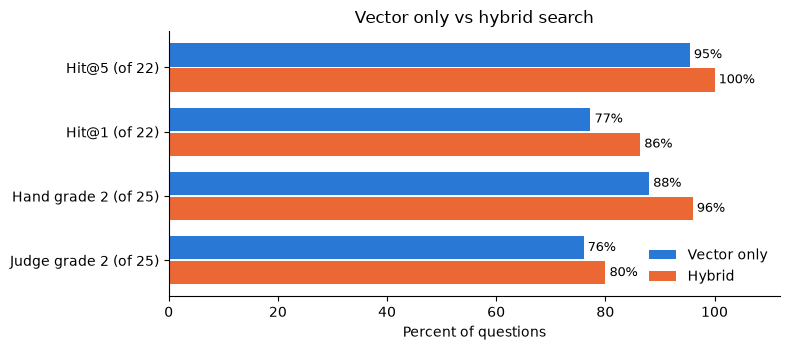

In [29]:
chart_rows = {
    "Hit@5 (of 22)": 22,
    "Hit@1 (of 22)": 22,
    "Hand grade 2 (of 25)": 25,
    "Judge grade 2 (of 25)": 25,
}
metric_keys = [
    "Hit@5 (22 in scope)",
    "Hit@1 (22 in scope)",
    "Hand grade 2 (all 25)",
    "Judge grade 2 (all 25)",
]
positions = np.arange(len(chart_rows))
height = 0.36

fig, ax = plt.subplots(figsize=(8, 3.6))
for offset, mode, color, label in (
    (0, "vector", "#2a78d6", "Vector only"),
    (1, "hybrid", "#eb6834", "Hybrid"),
):
    percents = [
        100 * scores[mode][k] / total
        for k, total in zip(metric_keys, chart_rows.values(), strict=True)
    ]
    bars = ax.barh(
        positions + (offset - 0.5) * (height + 0.03), percents, height, color=color, label=label
    )
    ax.bar_label(bars, labels=[f"{p:.0f}%" for p in percents], padding=3, fontsize=9)
ax.set_yticks(positions, chart_rows.keys())
ax.invert_yaxis()
ax.set_xlim(0, 112)
ax.set_xlabel("Percent of questions")
ax.set_title("Vector only vs hybrid search")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

**What this cell does:** lists every answer the hand grader did *not* mark as fully correct, and
any question whose correct page was missed.

**Why it matters:** the failures teach more than the averages. In hybrid mode the only answer the
hand grader marked down is q01, the home-loan rate question. It gives 7.25% but misses the range
that depends on the CIBIL score, because rate tables are mostly numbers and embed poorly. That
is a **retrieval** problem, and the fix suggested in the project README is a reranker or a
structured rate table.

In [30]:
for mode, rows in results.items():
    print(f"--- {mode.upper()} ---")
    for r in rows:
        missed_page = r["type"] != "out_of_scope" and r["hit_rank"] is None
        if r["hand_grade"] != 2 or missed_page:
            print(
                f"{r['id']}: hand grade {r['hand_grade']}, page rank {r['hit_rank'] or 'missed'}, "
                f"refused={r['refused']}\n     {r['question']}"
            )
    print()

--- VECTOR ---
q01: hand grade 1, page rank 1, refused=False
     What are the interest rates for a Bank of Maharashtra home loan?
q10: hand grade 1, page rank 1, refused=False
     Is collateral needed for an education loan?
q13: hand grade 0, page rank missed, refused=True
     How much can I borrow against my fixed deposit and is there a processing fee?

--- HYBRID ---
q01: hand grade 1, page rank 1, refused=False
     What are the interest rates for a Bank of Maharashtra home loan?



**What this cell does:** re-measures retrieval live, using the search code from this notebook.
Retrieval uses no language model, so this needs no key and costs nothing.

**Why it matters:** this checks our own work. If the code in this notebook is right, its scores
must match the saved run in the table above.

In [31]:
questions = [
    json.loads(line)
    for line in (ROOT / "eval" / "questions.jsonl").read_text(encoding="utf-8").splitlines()
    if line
]
in_scope = [q for q in questions if q["type"] != "out_of_scope"]


def retrieval_scores(mode: str) -> tuple[int, int]:
    """Count (hit@5, hit@1) over the in-scope questions."""
    hit5 = hit1 = 0
    for q in in_scope:
        accepted = {q["expected_url"], *q.get("alt_urls", [])}
        urls = [hit.chunk["url"] for hit in search(q["question"], mode)]
        hit5 += any(url in accepted for url in urls)
        hit1 += urls[0] in accepted
    return hit5, hit1


for mode in ("vector", "hybrid"):
    hit5, hit1 = retrieval_scores(mode)
    print(
        f"{mode:<7} live hit@5 {hit5}/22  hit@1 {hit1}/22   |   "
        f"saved run {scores[mode]['Hit@5 (22 in scope)']}/22 "
        f"and {scores[mode]['Hit@1 (22 in scope)']}/22"
    )

vector  live hit@5 21/22  hit@1 17/22   |   saved run 21/22 and 17/22


hybrid  live hit@5 22/22  hit@1 19/22   |   saved run 22/22 and 19/22


---
# Part 14: Cross-check against the real project code

This notebook re-writes the logic so it can be read cell by cell. The app runs the tested package
in `src/loan_assistant/`. A student should be able to trust that the two do the same thing, so we
test it instead of claiming it.

**What this cell does:** three checks.
1. The vectors we built match the project's saved index.
2. Our search returns the same chunks, in the same order, as the project's `Retriever`, for every
   test question in both modes.
3. Our prompt and number check behave the same as the project's.

In [32]:
from loan_assistant.rag.grounding import ground_answer as project_ground_answer  # noqa: E402
from loan_assistant.rag.index import load_index  # noqa: E402
from loan_assistant.rag.prompt import SYSTEM_PROMPT as PROJECT_SYSTEM_PROMPT  # noqa: E402
from loan_assistant.rag.retrieve import Retriever  # noqa: E402

saved_index, _ = load_index()
saved_vectors = saved_index.reconstruct_n(0, saved_index.ntotal)
print("Vectors match the saved index:", bool(np.allclose(saved_vectors, chunk_vectors, atol=1e-4)))

retriever = Retriever()
compared = differences = 0
for q in questions:
    for mode in ("vector", "hybrid"):
        ours = [hit.chunk["id"] for hit in search(q["question"], mode)]
        theirs = [rc.chunk["id"] for rc in retriever.search(q["question"], mode=mode)]
        compared += 1
        differences += ours != theirs
print(f"Search results compared: {compared}, differences: {differences}")

same_grounding = all(
    project_ground_answer(draft, page_text).text == ground_answer(draft, page_text)[0]
    for draft in examples.values()
)
print("Number check matches the project on the three examples:", same_grounding)
print("Prompt matches the project:", SYSTEM_PROMPT == PROJECT_SYSTEM_PROMPT)

Vectors match the saved index: True


Search results compared: 50, differences: 0
Number check matches the project on the three examples: True
Prompt matches the project: True


---
# Part 15: Next steps

### Run the app

Everything you just built is also available as a chat app. From the project root:

```bash
streamlit run deliverables/streamlit_app.py
```

### What you built

```
Official pages -> clean -> chunk -> embed -> FAISS + BM25
                                                 |
Question -> guardrails -> hybrid search -> prompt -> model -> number check -> cited answer
```

### The five ideas to remember

1. **Data quality comes first.** Cleaning removed about three quarters of the visible words.
2. **Chunking is a design decision.** Keep tables whole and keep the product name on every chunk.
3. **Two kinds of search beat one.** Meaning finds paraphrases, and keywords find exact terms.
4. **Check in code what must never happen.** A prompt is a request, not a guarantee.
5. **Measure, and report failures too.** Saying what does not work is part of the job.

### Exercises

| Level | Exercise | Where to change |
|---|---|---|
| Easy | Ask five questions of your own, and check each answer against its source link | Part 12 |
| Easy | Change `TOP_K` to 3 and then 10. What happens to hit@5? | Part 1, then Part 13 |
| Medium | Change `MIN_SCORE` to 0.60 and to 0.80. Which questions change decision? | Part 8 |
| Medium | Add a rule to the prompt that answers must start with the loan's name | Part 9 |
| Medium | Add three test questions of your own and score the retrieval | Part 13 |
| Hard | Add a cross-encoder reranker to try to fix the q01 failure | Part 7 |
| Hard | Swap in another embedding model and compare the scores | Part 5 |

### Disclaimer

This is a learning project and is not affiliated with Bank of Maharashtra. Answers come from
pages scraped on 28 October 2026, and rates change. It is not financial advice: always confirm
terms with the bank.